1. Simple Linear Regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# Dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)

Y = np.array([
    30000, 35000, 40000, 45000, 50000,
    55000, 60000, 65000, 70000, 75000
])

In [3]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X, Y)


LinearRegression()

In [4]:
# Prediction
Y_pred = model.predict(X)

In [5]:
# Display coefficient and intercept
print("Simple Linear Regression")
print("------------------------")
print("Slope (Coefficient):", model.coef_[0])
print("Intercept:", model.intercept_)

Simple Linear Regression
------------------------
Slope (Coefficient): 5000.000000000002
Intercept: 24999.99999999999


In [6]:
# Predict salary for 11 years of experience
experience = np.array([[11]])
predicted_salary = model.predict(experience)

print("Predicted Salary for 11 years:",
      predicted_salary[0])


Predicted Salary for 11 years: 80000.00000000001


In [7]:
# Calculate accuracy measures
mse = mean_squared_error(Y, Y_pred)
r2 = r2_score(Y, Y_pred)

print("Mean Squared Error:", mse)
print("R2 Score:", r2)


Mean Squared Error: 1.588186776101813e-23
R2 Score: 1.0


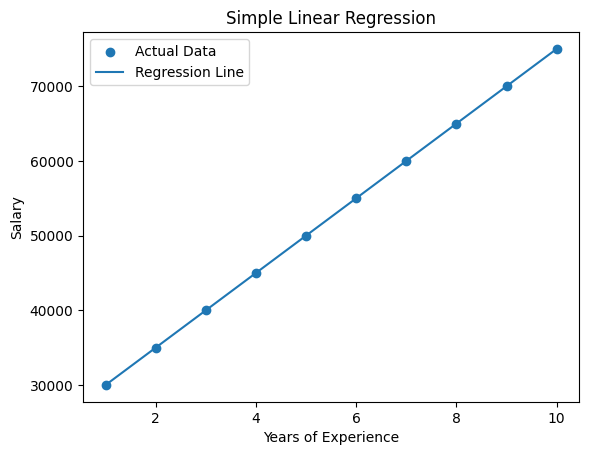

In [8]:
# Plot
plt.scatter(X, Y, label="Actual Data")
plt.plot(X, Y_pred, label="Regression Line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression")

plt.legend()
plt.show()

2. Multiple Linear Regression

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [10]:
# Create dataset
data = {
    "Area": [1000, 1200, 1500, 1800, 2000,
             2200, 2500, 2800, 3000, 3500],

    "Bedrooms": [2, 2, 3, 3, 3,
                 4, 4, 4, 5, 5],

    "Age": [10, 8, 5, 7, 4,
            3, 6, 2, 5, 1],

    "Price": [40, 45, 55, 60, 68,
              75, 82, 90, 98, 110]
}

In [11]:
df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Independent variables
X = df[["Area", "Bedrooms", "Age"]]

# Dependent variable
Y = df["Price"]

Dataset:
   Area  Bedrooms  Age  Price
0  1000         2   10     40
1  1200         2    8     45
2  1500         3    5     55
3  1800         3    7     60
4  2000         3    4     68
5  2200         4    3     75
6  2500         4    6     82
7  2800         4    2     90
8  3000         5    5     98
9  3500         5    1    110


In [12]:
# Split data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


In [15]:
# Create model
model = LinearRegression()

# Train model
model.fit(X_train, Y_train)

LinearRegression()

In [16]:
# Prediction
Y_pred = model.predict(X_test)

# Display coefficients
print("\nMultiple Linear Regression")
print("--------------------------")

print("Intercept:", model.intercept_)


Multiple Linear Regression
--------------------------
Intercept: 13.054543388508016


In [17]:
print("Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)


Coefficients:
Area : 0.024781637059202288
Bedrooms : 2.0535585773266236
Age : -0.280481799931821


In [18]:
# Display actual and predicted values
result = pd.DataFrame({
    "Actual Price": Y_test.values,
    "Predicted Price": Y_pred
})

In [19]:
print("\nActual vs Predicted:")
print(result)


Actual vs Predicted:
   Actual Price  Predicted Price
0            98        96.264838
1            45        44.655771


In [20]:
# Calculate evaluation metrics
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("\nMean Squared Error:", mse)
print("R2 Score:", r2)


Mean Squared Error: 1.5646397317744778
R2 Score: 0.9977719619341054


In [21]:
# Predict price for a new house
new_house = pd.DataFrame({
    "Area": [2000],
    "Bedrooms": [3],
    "Age": [5]
})

predicted_price = model.predict(new_house)

print("\nPredicted Price of New House:",
      predicted_price[0], "Lakhs")


Predicted Price of New House: 67.37608423923336 Lakhs
